# 05 · Selección ANOVA y reducción PCA

**Jorge Javier Palma Martínez · ML1 FIUNA · 2026**

Protocolo: `deduplicated-v2-2026-11-22`.

SelectKBest con ANOVA compara 40,80,160 descriptores. PCA compara 32,64,128 componentes después de StandardScaler. Cada transformación se ajusta con train dentro del Pipeline; validación elige la alternativa. La columna constante no aporta discriminación y sklearn la descarta del ranking útil. Esta selección no utiliza importancias calculadas con test.

Se prueban SVM con selección (C=10/50), XGBoost con selección (200 rondas) y SVM con PCA (C=10). Las representaciones se comparan en validación; no se afirma que reducir siempre mejore. La selección final fue SVM ANOVA160 C=10, frente a 320 entradas originales.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/workflow.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src import workflow
# False: show the executed experiment exports; True: recompute this stage.
RECOMPUTE=False


## Ejecutar o consultar la etapa

Los resultados mostrados se cargan de los artefactos calculados por `python scripts/run_pipeline.py`. Para reconstruir, ejecutar los seis notebooks en orden con `RECOMPUTE=True`; para leer la entrega, dejarlo en `False`. Las implementaciones completas están en `src/workflow.py`.

In [2]:
if RECOMPUTE:
    workflow.feature_engineering()
display(pd.DataFrame(json.loads((ROOT/'reports/feature_validation.json').read_text(encoding='utf-8'))))

,Modelo,family,input_kind,Accuracy (%),Balanced Acc (%),F1 Macro,F1 Weighted,Precision Macro,Recall Macro,seconds
0,SVM ANOVA160 C=10,SVM,tabular,59.7458,58.3888,0.588111,0.592935,0.597360,0.583888,0.59
1,SVM ANOVA80 C=10,SVM,tabular,60.1695,57.4478,0.583041,0.601872,0.596489,0.574478,0.45
2,SVM ANOVA160 C=50,SVM,tabular,57.6271,56.6519,0.572383,0.572125,0.584187,0.566519,0.59
3,SVM PCA32 C=10,SVM,tabular,58.0508,56.0974,0.568417,0.579938,0.579346,0.560974,0.43
4,SVM ANOVA80 C=50,SVM,tabular,58.0508,55.0271,0.560597,0.577995,0.577399,0.550271,0.47
5,SVM PCA128 C=10,SVM,tabular,56.3559,54.7987,0.558577,0.559513,0.577524,0.547987,0.58
6,SVM PCA64 C=10,SVM,tabular,56.3559,54.7245,0.558136,0.562560,0.576116,0.547245,0.46
7,XGBoost ANOVA160,XGBoost,tabular,59.3220,53.9771,0.540304,0.575044,0.566939,0.539771,6.48
8,XGBoost ANOVA80,XGBoost,tabular,57.6271,52.4668,0.529353,0.562397,0.545912,0.524668,3.07
9,SVM ANOVA40 C=10,SVM,tabular,55.0847,51.8078,0.522170,0.544238,0.530391,0.518078,0.40


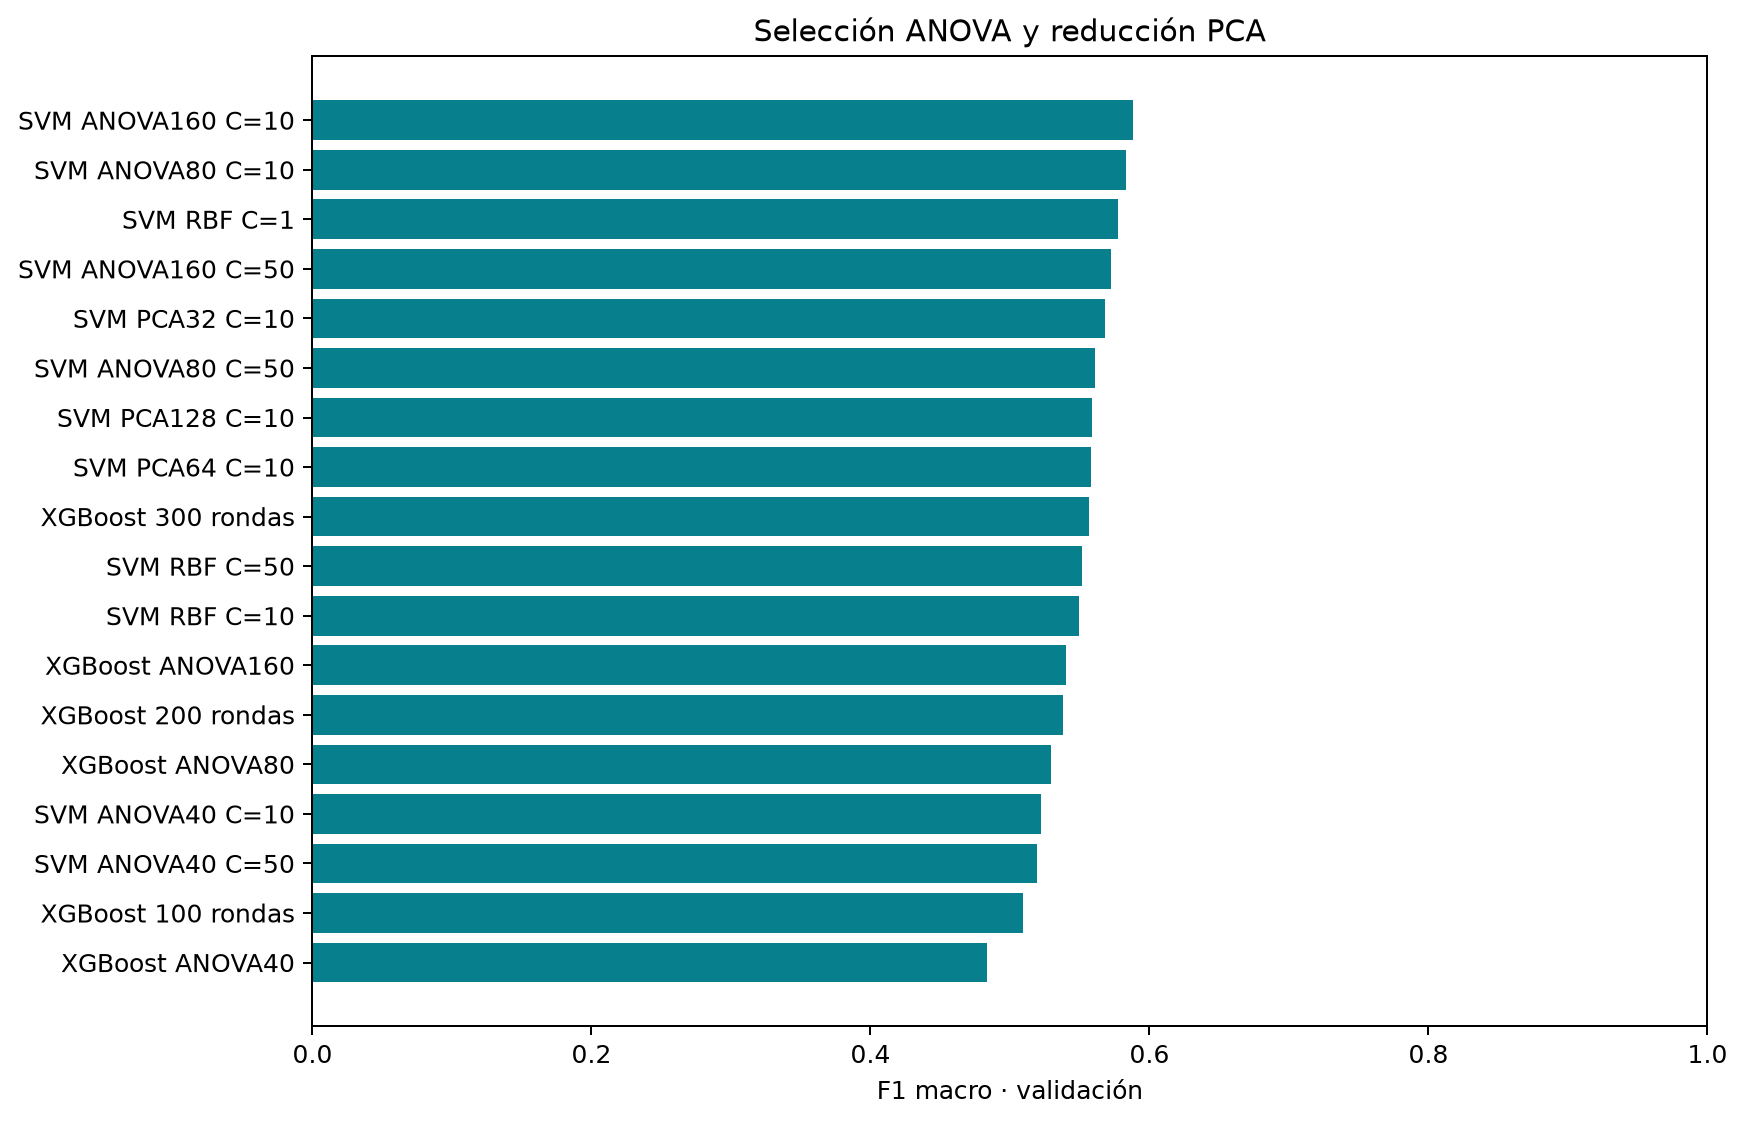

In [3]:
display(Image(filename=str(ROOT/'reports/figures/feature_engineering_validation.png')))